In [759]:
from Bio import Entrez,SeqIO,Seq
from Bio.SeqUtils import GC123,molecular_weight
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

In [279]:
species = {
    "Homo sapiens (Human)": "NC_012920.1",
    "Pan troglodytes (Chimpanzee)": "NC_001643.1",
    "Gorilla gorilla (Gorilla)": "NC_001645.1",
    "Pongo abelii (Sumatran Orangutan)": "NC_002083.1",
    "Mus musculus (House Mouse)": "NC_005089.1",
    "Rattus norvegicus (Brown Rat)": "NC_001665.2",
    "Canis lupus familiaris (Dog)": "NC_002008.4",
    "Felis catus (Domestic Cat)": "NC_001700.1",
    "Canis lupus (Gray Wolf)": "NC_009686.1",
    "Bos taurus (Domestic Cattle)": "NC_006853.1",
    "Sus scrofa (Domestic Pig)": "NC_000845.1",
    "Equus caballus (Horse)": "NC_001640.1",
    "Ovis aries (Sheep)": "NC_001941.1",
    "Capra hircus (Goat)": "NC_005044.2",
    "Delphinapterus leucas (Beluga Whale)": "NC_004029.2",
    "Balaenoptera musculus (Blue Whale)": "NC_001601.1",
    "Physeter macrocephalus (Sperm Whale)": "NC_002503.1",
    "Gallus gallus (Chicken)": "NC_001323.1",
    "Anas platyrhynchos (Mallard Duck)": "NC_009684.1",
    "Crocodylus siamensis (Siamese Crocodile)": "NC_012812.1",
    "Chelonia mydas (Green Sea Turtle)": "NC_000886.1",
    "Xenopus laevis (African Clawed Frog)": "NC_001573.1",
    "Xenopus tropicalis (Western Clawed Frog)": "NC_006839.1",
    "Danio rerio (Zebrafish)": "NC_002333.2",
    "Takifugu rubripes (Pufferfish)": "NC_004299.1",
  

}

In [280]:
from collections import Counter

Entrez.email=''
Dataset=[]
for species,accessions in species.items():
    handle=Entrez.efetch(db='nucleotide',id=accessions,rettype='gb',retmode='text')
    record=SeqIO.read(handle,'genbank')
    handle.close()
    for rec in record.features:
        record_gene=rec.qualifiers.get("gene",[''])[0]
        recordFeature=rec.extract(record.seq)
        count_from_DNA=Counter(recordFeature)
        try:
            Dataset.append({
                'species':species,
                'Gene': str(record_gene),
                'DNA': str(recordFeature),
                'GC%':GC123(record.seq)[0],
                'AT%':100-GC123(record.seq)[0],
                "DNA_Length":len(recordFeature),
                "A":count_from_DNA['A'],
                'T':count_from_DNA['T'],
                'G':count_from_DNA['G'],
                'C':count_from_DNA['C'],
                'GC_skew':((count_from_DNA['G']-count_from_DNA['C'])/(count_from_DNA['G']+count_from_DNA['C'])),
                'AT_skew':((count_from_DNA['A']-count_from_DNA['T'])/(count_from_DNA['A']+count_from_DNA['T'])),
                'RNA':recordFeature.transcribe(),
                'RNA_Length':len(recordFeature.transcribe()),
                'protien':recordFeature.translate(),
                'Protien_length':len(recordFeature.translate()) ,
                'Purine_Content':(count_from_DNA['A']+count_from_DNA['T'])/len(str(recordFeature)),
                'Pyrimidine_Content':(count_from_DNA['G']+count_from_DNA['C'])/len(str(recordFeature)),
                'AT_GCRatio':(count_from_DNA['A']+count_from_DNA['T'])/(count_from_DNA['G']+count_from_DNA['C']),
                "Protien_Density":len(recordFeature.translate())/len(recordFeature)
                  })
        except Exception as e:
            print(species,e,recordFeature)

df=pd.DataFrame(Dataset)

C:\Users\saini\AppData\Roaming\Python\Python314\site-packages\Bio\Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


Homo sapiens (Human) division by zero N
Mus musculus (House Mouse) division by zero T
Mus musculus (House Mouse) division by zero G
Mus musculus (House Mouse) division by zero T
Mus musculus (House Mouse) division by zero AAAAAAAATT
Mus musculus (House Mouse) division by zero G
Mus musculus (House Mouse) division by zero A
Mus musculus (House Mouse) division by zero T


In [281]:
df.to_csv(r"data\Milestone_2.csv",index=False)

In [328]:
df=pd.read_csv("data\Milestone_2.csv")
df=df.iloc[:,:]
df

,species,Gene,DNA,GC%,AT%,DNA_Length,A,T,G,C,GC_skew,AT_skew,RNA,RNA_Length,protien,Protien_length,Purine_Content,Pyrimidine_Content,AT_GCRatio,Protien_Density
0,Homo sapiens (Human),NaN,GATCACAGGTCTATCACCCTATTAACCACTCACGGGAGCTCTCCAT...,44.362627,55.637373,16569,5124,4094,2169,5181,-0.409796,0.111738,GAUCACAGGUCUAUCACCCUAUUAACCACUCACGGGAGCUCUCCAU...,16569,DHRSITLLTTHGSSPCIWYFRLGGMHAIALRDAGAGAPYVAVSVFD...,5523,0.556340,0.443599,1.254150,0.333333
1,Homo sapiens (Human),NaN,TGTGGGGGGTGTCTTTGGGGTTTGGTTGGTTCGGGGTATGGGGTTA...,44.362627,55.637373,1122,260,339,371,152,0.418738,-0.131886,UGUGGGGGGUGUCUUUGGGGUUUGGUUGGUUCGGGGUAUGGGGUUA...,1122,CGGCLWGLVGSGYGVSSGVCVLGRMGGGCIDEISSMGVGGENNVLV...,374,0.533868,0.466132,1.145315,0.333333
2,Homo sapiens (Human),TRNF,GTTTATGTAGCTTACCTCCTCAAAGCAATACACTGAAAATGTTTAG...,44.362627,55.637373,71,24,18,10,19,-0.310345,0.142857,GUUUAUGUAGCUUACCUCCUCAAAGCAAUACACUGAAAAUGUUUAG...,71,VYVAYLLKAIH*KCLDGLTSPHK,23,0.591549,0.408451,1.448276,0.323944
3,Homo sapiens (Human),TRNF,GTTTATGTAGCTTACCTCCTCAAAGCAATACACTGAAAATGTTTAG...,44.362627,55.637373,71,24,18,10,19,-0.310345,0.142857,GUUUAUGUAGCUUACCUCCUCAAAGCAAUACACUGAAAAUGUUUAG...,71,VYVAYLLKAIH*KCLDGLTSPHK,23,0.591549,0.408451,1.448276,0.323944
4,Homo sapiens (Human),RNR1,AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACA...,44.362627,55.637373,954,315,205,181,253,-0.165899,0.211538,AAUAGGUUUGGUCCUAGCCUUUCUAUUAGCUCUUAGUAAGAUUACA...,954,NRFGPSLSISS**DYTCKHPRSSEFTL*ITTIKRNKHQARSNAAQN...,318,0.545073,0.454927,1.198157,0.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1754,Takifugu rubripes (Pufferfish),NaN,GCATTAGTAGCTCAGATTCAGAGCGTCGGTCTTGTAAACCGAATGT...,44.239071,55.760929,72,17,20,18,17,0.028571,-0.081081,GCAUUAGUAGCUCAGAUUCAGAGCGUCGGUCUUGUAAACCGAAUGU...,72,ALVAQIQSVGLVNRMSGVKIPPYA,24,0.513889,0.486111,1.057143,0.333333
1755,Takifugu rubripes (Pufferfish),NaN,GCATTAGTAGCTCAGATTCAGAGCGTCGGTCTTGTAAACCGAATGT...,44.239071,55.760929,72,17,20,18,17,0.028571,-0.081081,GCAUUAGUAGCUCAGAUUCAGAGCGUCGGUCUUGUAAACCGAAUGU...,72,ALVAQIQSVGLVNRMSGVKIPPYA,24,0.513889,0.486111,1.057143,0.333333
1756,Takifugu rubripes (Pufferfish),NaN,TCAAAAAGTAGTTTAATTAAGAATGCTGGCTTTGGGAGCCAGTGGT...,44.239071,55.760929,71,17,24,21,9,0.400000,-0.170732,UCAAAAAGUAGUUUAAUUAAGAAUGCUGGCUUUGGGAGCCAGUGGU...,71,SKSSLIKNAGFGSQWWGLKSLLF,23,0.577465,0.422535,1.366667,0.323944
1757,Takifugu rubripes (Pufferfish),NaN,TCAAAAAGTAGTTTAATTAAGAATGCTGGCTTTGGGAGCCAGTGGT...,44.239071,55.760929,71,17,24,21,9,0.400000,-0.170732,UCAAAAAGUAGUUUAAUUAAGAAUGCUGGCUUUGGGAGCCAGUGGU...,71,SKSSLIKNAGFGSQWWGLKSLLF,23,0.577465,0.422535,1.366667,0.323944


In [329]:
alias_to_canonical = {
    "12S rRNA": "MT-RNR1",
    "RNR1": "MT-RNR1",
    "mt-Rnr1": "MT-RNR1",
    "mt-rnr1": "MT-RNR1",

    "16S rRNA": "MT-RNR2",
    "RNR2": "MT-RNR2",
    "mt-Rnr2": "MT-RNR2",
    "mt-rnr2": "MT-RNR2",

    "TRNA": "MT-TA",
    "TrnA": "MT-TA",
    "Trna": "MT-TA",
    "tRNA-Ala": "MT-TA",
    "trnA": "MT-TA",

    "TRNC": "MT-TC",
    "TrnC": "MT-TC",
    "Trnc": "MT-TC",
    "tRNA-Cys": "MT-TC",
    "trnC": "MT-TC",

    "TRND": "MT-TD",
    "TrnD": "MT-TD",
    "Trnd": "MT-TD",
    "tRNA-Asp": "MT-TD",
    "trnD": "MT-TD",

    "TRNE": "MT-TE",
    "TrnE": "MT-TE",
    "Trne": "MT-TE",
    "trnE": "MT-TE",

    "TRNF": "MT-TF",
    "TrnF": "MT-TF",
    "Trnf": "MT-TF",
    "tRNA-Phe": "MT-TF",
    "trnF": "MT-TF",

    "TRNG": "MT-TG",
    "TrnG": "MT-TG",
    "Trng": "MT-TG",
    "tRNA-Gly": "MT-TG",
    "trnG": "MT-TG",

    "TRNH": "MT-TH",
    "TrnH": "MT-TH",
    "Trnh": "MT-TH",
    "tRNA-His": "MT-TH",
    "trnH": "MT-TH",

    "TRNI": "MT-TI",
    "TrnI": "MT-TI",
    "Trni": "MT-TI",
    "tRNA-Ile": "MT-TI",
    "trnI": "MT-TI",

    "TRNK": "MT-TK",
    "TrnK": "MT-TK",
    "Trnk": "MT-TK",
    "tRNA-Lys": "MT-TK",
    "trnK": "MT-TK",

    "TRNL1": "MT-TL1",
    "TrnL1": "MT-TL1",
    "Trnl1": "MT-TL1",
    "tRNA-Leu (UUR)": "MT-TL1",
    "trnL1": "MT-TL1",

    "TRNL2": "MT-TL2",
    "TrnL2": "MT-TL2",
    "Trnl2": "MT-TL2",
    "tRNA-Leu (CUN)": "MT-TL2",
    "trnL2": "MT-TL2",

    "TRNM": "MT-TM",
    "TrnM": "MT-TM",
    "Trnm": "MT-TM",
    "tRNA-Met": "MT-TM",
    "trnM": "MT-TM",

    "TRNN": "MT-TN",
    "TrnN": "MT-TN",
    "Trnn": "MT-TN",
    "tRNA-Asn": "MT-TN",
    "trnN": "MT-TN",

    "TRNP": "MT-TP",
    "TrnP": "MT-TP",
    "Trnp": "MT-TP",
    "tRNA-Pro": "MT-TP",
    "trnP": "MT-TP",

    "TRNQ": "MT-TQ",
    "TrnQ": "MT-TQ",
    "Trnq": "MT-TQ",
    "tRNA-Gln": "MT-TQ",
    "trnQ": "MT-TQ",

    "TRNR": "MT-TR",
    "TrnR": "MT-TR",
    "Trnr": "MT-TR",
    "tRNA-Arg": "MT-TR",
    "trnR": "MT-TR",

    "TRNS1": "MT-TS1",
    "TrnS1": "MT-TS1",
    "Trns1": "MT-TS1",
    "tRNA-Ser (UCN)": "MT-TS1",
    "trnS1": "MT-TS1",

    "TRNS2": "MT-TS2",
    "TrnS2": "MT-TS2",
    "Trns2": "MT-TS2",
    "tRNA-Ser (AGY)": "MT-TS2",
    "trnS2": "MT-TS2",

    "TRNT": "MT-TT",
    "TrnT": "MT-TT",
    "Trnt": "MT-TT",
    "tRNA-Thr": "MT-TT",
    "trnT": "MT-TT",

    "TRNV": "MT-TV",
    "TrnV": "MT-TV",
    "Trnv": "MT-TV",
    "tRNA-Val": "MT-TV",
    "trnV": "MT-TV",

    "TRNW": "MT-TW",
    "TrnW": "MT-TW",
    "Trnw": "MT-TW",
    "tRNA-Trp": "MT-TW",
    "trnW": "MT-TW",

    "TRNY": "MT-TY",
    "TrnY": "MT-TY",
    "Trny": "MT-TY",
    "tRNA-Tyr": "MT-TY",
    "trnY": "MT-TY",
}

In [330]:

for i in range(len(df)):
    if pd.isna(df.loc[i,'Gene']):
        df=df.drop(i,axis=0,)
df['Gene']=df["Gene"].replace(alias_to_canonical)
        
df
    

,species,Gene,DNA,GC%,AT%,DNA_Length,A,T,G,C,GC_skew,AT_skew,RNA,RNA_Length,protien,Protien_length,Purine_Content,Pyrimidine_Content,AT_GCRatio,Protien_Density
2,Homo sapiens (Human),MT-TF,GTTTATGTAGCTTACCTCCTCAAAGCAATACACTGAAAATGTTTAG...,44.362627,55.637373,71,24,18,10,19,-0.310345,0.142857,GUUUAUGUAGCUUACCUCCUCAAAGCAAUACACUGAAAAUGUUUAG...,71,VYVAYLLKAIH*KCLDGLTSPHK,23,0.591549,0.408451,1.448276,0.323944
3,Homo sapiens (Human),MT-TF,GTTTATGTAGCTTACCTCCTCAAAGCAATACACTGAAAATGTTTAG...,44.362627,55.637373,71,24,18,10,19,-0.310345,0.142857,GUUUAUGUAGCUUACCUCCUCAAAGCAAUACACUGAAAAUGUUUAG...,71,VYVAYLLKAIH*KCLDGLTSPHK,23,0.591549,0.408451,1.448276,0.323944
4,Homo sapiens (Human),MT-RNR1,AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACA...,44.362627,55.637373,954,315,205,181,253,-0.165899,0.211538,AAUAGGUUUGGUCCUAGCCUUUCUAUUAGCUCUUAGUAAGAUUACA...,954,NRFGPSLSISS**DYTCKHPRSSEFTL*ITTIKRNKHQARSNAAQN...,318,0.545073,0.454927,1.198157,0.333333
5,Homo sapiens (Human),MT-RNR1,AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACA...,44.362627,55.637373,954,315,205,181,253,-0.165899,0.211538,AAUAGGUUUGGUCCUAGCCUUUCUAUUAGCUCUUAGUAAGAUUACA...,954,NRFGPSLSISS**DYTCKHPRSSEFTL*ITTIKRNKHQARSNAAQN...,318,0.545073,0.454927,1.198157,0.333333
6,Homo sapiens (Human),MT-TV,CAGAGTGTAGCTTAACACAAAGCACCCAACTTACACTTAGGAGATT...,44.362627,55.637373,69,23,17,11,18,-0.241379,0.150000,CAGAGUGUAGCUUAACACAAAGCACCCAACUUACACUUAGGAGAUU...,69,QSVA*HKAPNLHLGDFNLT*PL*,23,0.579710,0.420290,1.379310,0.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1747,Takifugu rubripes (Pufferfish),ND5,ATGCACTCCACCCCTCTAATTATAACATCTACCCTAATTATCATTT...,44.239071,55.760929,1839,537,509,218,575,-0.450189,0.026769,AUGCACUCCACCCCUCUAAUUAUAACAUCUACCCUAAUUAUCAUUU...,1839,MHSTPLIITSTLIIIFALLIYPVLITFSPKPQNPN*ALIQVKTAVK...,613,0.568787,0.431213,1.319042,0.333333
1748,Takifugu rubripes (Pufferfish),ND6,ATGTTTTATGCGCTTGTTTTTCTTTTATTAGGGATGTTGGTTGTAA...,44.239071,55.760929,522,89,210,157,66,0.408072,-0.404682,AUGUUUUAUGCGCUUGUUUUUCUUUUAUUAGGGAUGUUGGUUGUAA...,522,MFYALVFLLLGMLVVIIVLSTNPAPFYGVFNLVLVALLCCGASVLH...,174,0.572797,0.427203,1.340807,0.333333
1749,Takifugu rubripes (Pufferfish),ND6,ATGTTTTATGCGCTTGTTTTTCTTTTATTAGGGATGTTGGTTGTAA...,44.239071,55.760929,522,89,210,157,66,0.408072,-0.404682,AUGUUUUAUGCGCUUGUUUUUCUUUUAUUAGGGAUGUUGGUUGUAA...,522,MFYALVFLLLGMLVVIIVLSTNPAPFYGVFNLVLVALLCCGASVLH...,174,0.572797,0.427203,1.340807,0.333333
1752,Takifugu rubripes (Pufferfish),CYTB,ATGGCCAGCCTACGCAAAACCCACCCCCTACTAAAAATCGTAAACG...,44.239071,55.760929,1137,303,320,161,353,-0.373541,-0.027287,AUGGCCAGCCUACGCAAAACCCACCCCCUACUAAAAAUCGUAAACG...,1137,MASLRKTHPLLKIVNDIVIDLPTPSNISA**NFGSLLGLCLITQII...,379,0.547933,0.452067,1.212062,0.333333


In [331]:
df.drop_duplicates(inplace=True,ignore_index=True)

In [332]:
df

,species,Gene,DNA,GC%,AT%,DNA_Length,A,T,G,C,GC_skew,AT_skew,RNA,RNA_Length,protien,Protien_length,Purine_Content,Pyrimidine_Content,AT_GCRatio,Protien_Density
0,Homo sapiens (Human),MT-TF,GTTTATGTAGCTTACCTCCTCAAAGCAATACACTGAAAATGTTTAG...,44.362627,55.637373,71,24,18,10,19,-0.310345,0.142857,GUUUAUGUAGCUUACCUCCUCAAAGCAAUACACUGAAAAUGUUUAG...,71,VYVAYLLKAIH*KCLDGLTSPHK,23,0.591549,0.408451,1.448276,0.323944
1,Homo sapiens (Human),MT-RNR1,AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACA...,44.362627,55.637373,954,315,205,181,253,-0.165899,0.211538,AAUAGGUUUGGUCCUAGCCUUUCUAUUAGCUCUUAGUAAGAUUACA...,954,NRFGPSLSISS**DYTCKHPRSSEFTL*ITTIKRNKHQARSNAAQN...,318,0.545073,0.454927,1.198157,0.333333
2,Homo sapiens (Human),MT-TV,CAGAGTGTAGCTTAACACAAAGCACCCAACTTACACTTAGGAGATT...,44.362627,55.637373,69,23,17,11,18,-0.241379,0.150000,CAGAGUGUAGCUUAACACAAAGCACCCAACUUACACUUAGGAGAUU...,69,QSVA*HKAPNLHLGDFNLT*PL*,23,0.579710,0.420290,1.379310,0.333333
3,Homo sapiens (Human),MT-RNR2,GCTAAACCTAGCCCCAAACCCACTCCACCTTACTACCAGACAACCT...,44.362627,55.637373,1559,547,344,270,397,-0.190405,0.227834,GCUAAACCUAGCCCCAAACCCACUCCACCUUACUACCAGACAACCU...,1559,AKPSPKPTPPYYQTTLAKPFTQIKYRR*KLKPGAIDIVPQGKDEKL...,519,0.571520,0.427838,1.335832,0.332906
4,Homo sapiens (Human),MT-TL1,GTTAAGATGGCAGAGCCCGGTAATCGCATAAAACTTAAAACTTTAC...,44.362627,55.637373,75,25,21,13,16,-0.103448,0.086957,GUUAAGAUGGCAGAGCCCGGUAAUCGCAUAAAACUUAAAACUUUAC...,75,VKMAEPGNRIKLKTLQSEVQFLFLT,25,0.613333,0.386667,1.586207,0.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
428,Takifugu rubripes (Pufferfish),ND4L,ATGACCCTCATCCAACTCTCATTCACCTCAATCTTCTTCCTAGGAC...,44.239071,55.760929,297,75,84,41,97,-0.405797,-0.056604,AUGACCCUCAUCCAACUCUCAUUCACCUCAAUCUUCUUCCUAGGAC...,297,MTLIQLSFTSIFFLGLFGLAFYRVHLLSALLCLESIILALFLALST...,99,0.535354,0.464646,1.152174,0.333333
429,Takifugu rubripes (Pufferfish),ND4,ATGCTAAAAATCCTAATCCCAACCACTATACTTATCCTAGCAACAT...,44.239071,55.760929,1381,375,364,198,444,-0.383178,0.014885,AUGCUAAAAAUCCUAAUCCCAACCACUAUACUUAUCCUAGCAACAU...,1381,MLKILIPTTILILAT*LTPPK*LWPSSLLNSLLIALTSLLWLKNAS...,460,0.535119,0.464881,1.151090,0.333092
430,Takifugu rubripes (Pufferfish),ND5,ATGCACTCCACCCCTCTAATTATAACATCTACCCTAATTATCATTT...,44.239071,55.760929,1839,537,509,218,575,-0.450189,0.026769,AUGCACUCCACCCCUCUAAUUAUAACAUCUACCCUAAUUAUCAUUU...,1839,MHSTPLIITSTLIIIFALLIYPVLITFSPKPQNPN*ALIQVKTAVK...,613,0.568787,0.431213,1.319042,0.333333
431,Takifugu rubripes (Pufferfish),ND6,ATGTTTTATGCGCTTGTTTTTCTTTTATTAGGGATGTTGGTTGTAA...,44.239071,55.760929,522,89,210,157,66,0.408072,-0.404682,AUGUUUUAUGCGCUUGUUUUUCUUUUAUUAGGGAUGUUGGUUGUAA...,522,MFYALVFLLLGMLVVIIVLSTNPAPFYGVFNLVLVALLCCGASVLH...,174,0.572797,0.427203,1.340807,0.333333


In [743]:
df.to_csv("data/Milestone_2_Cleaned.csv")

<Axes: >

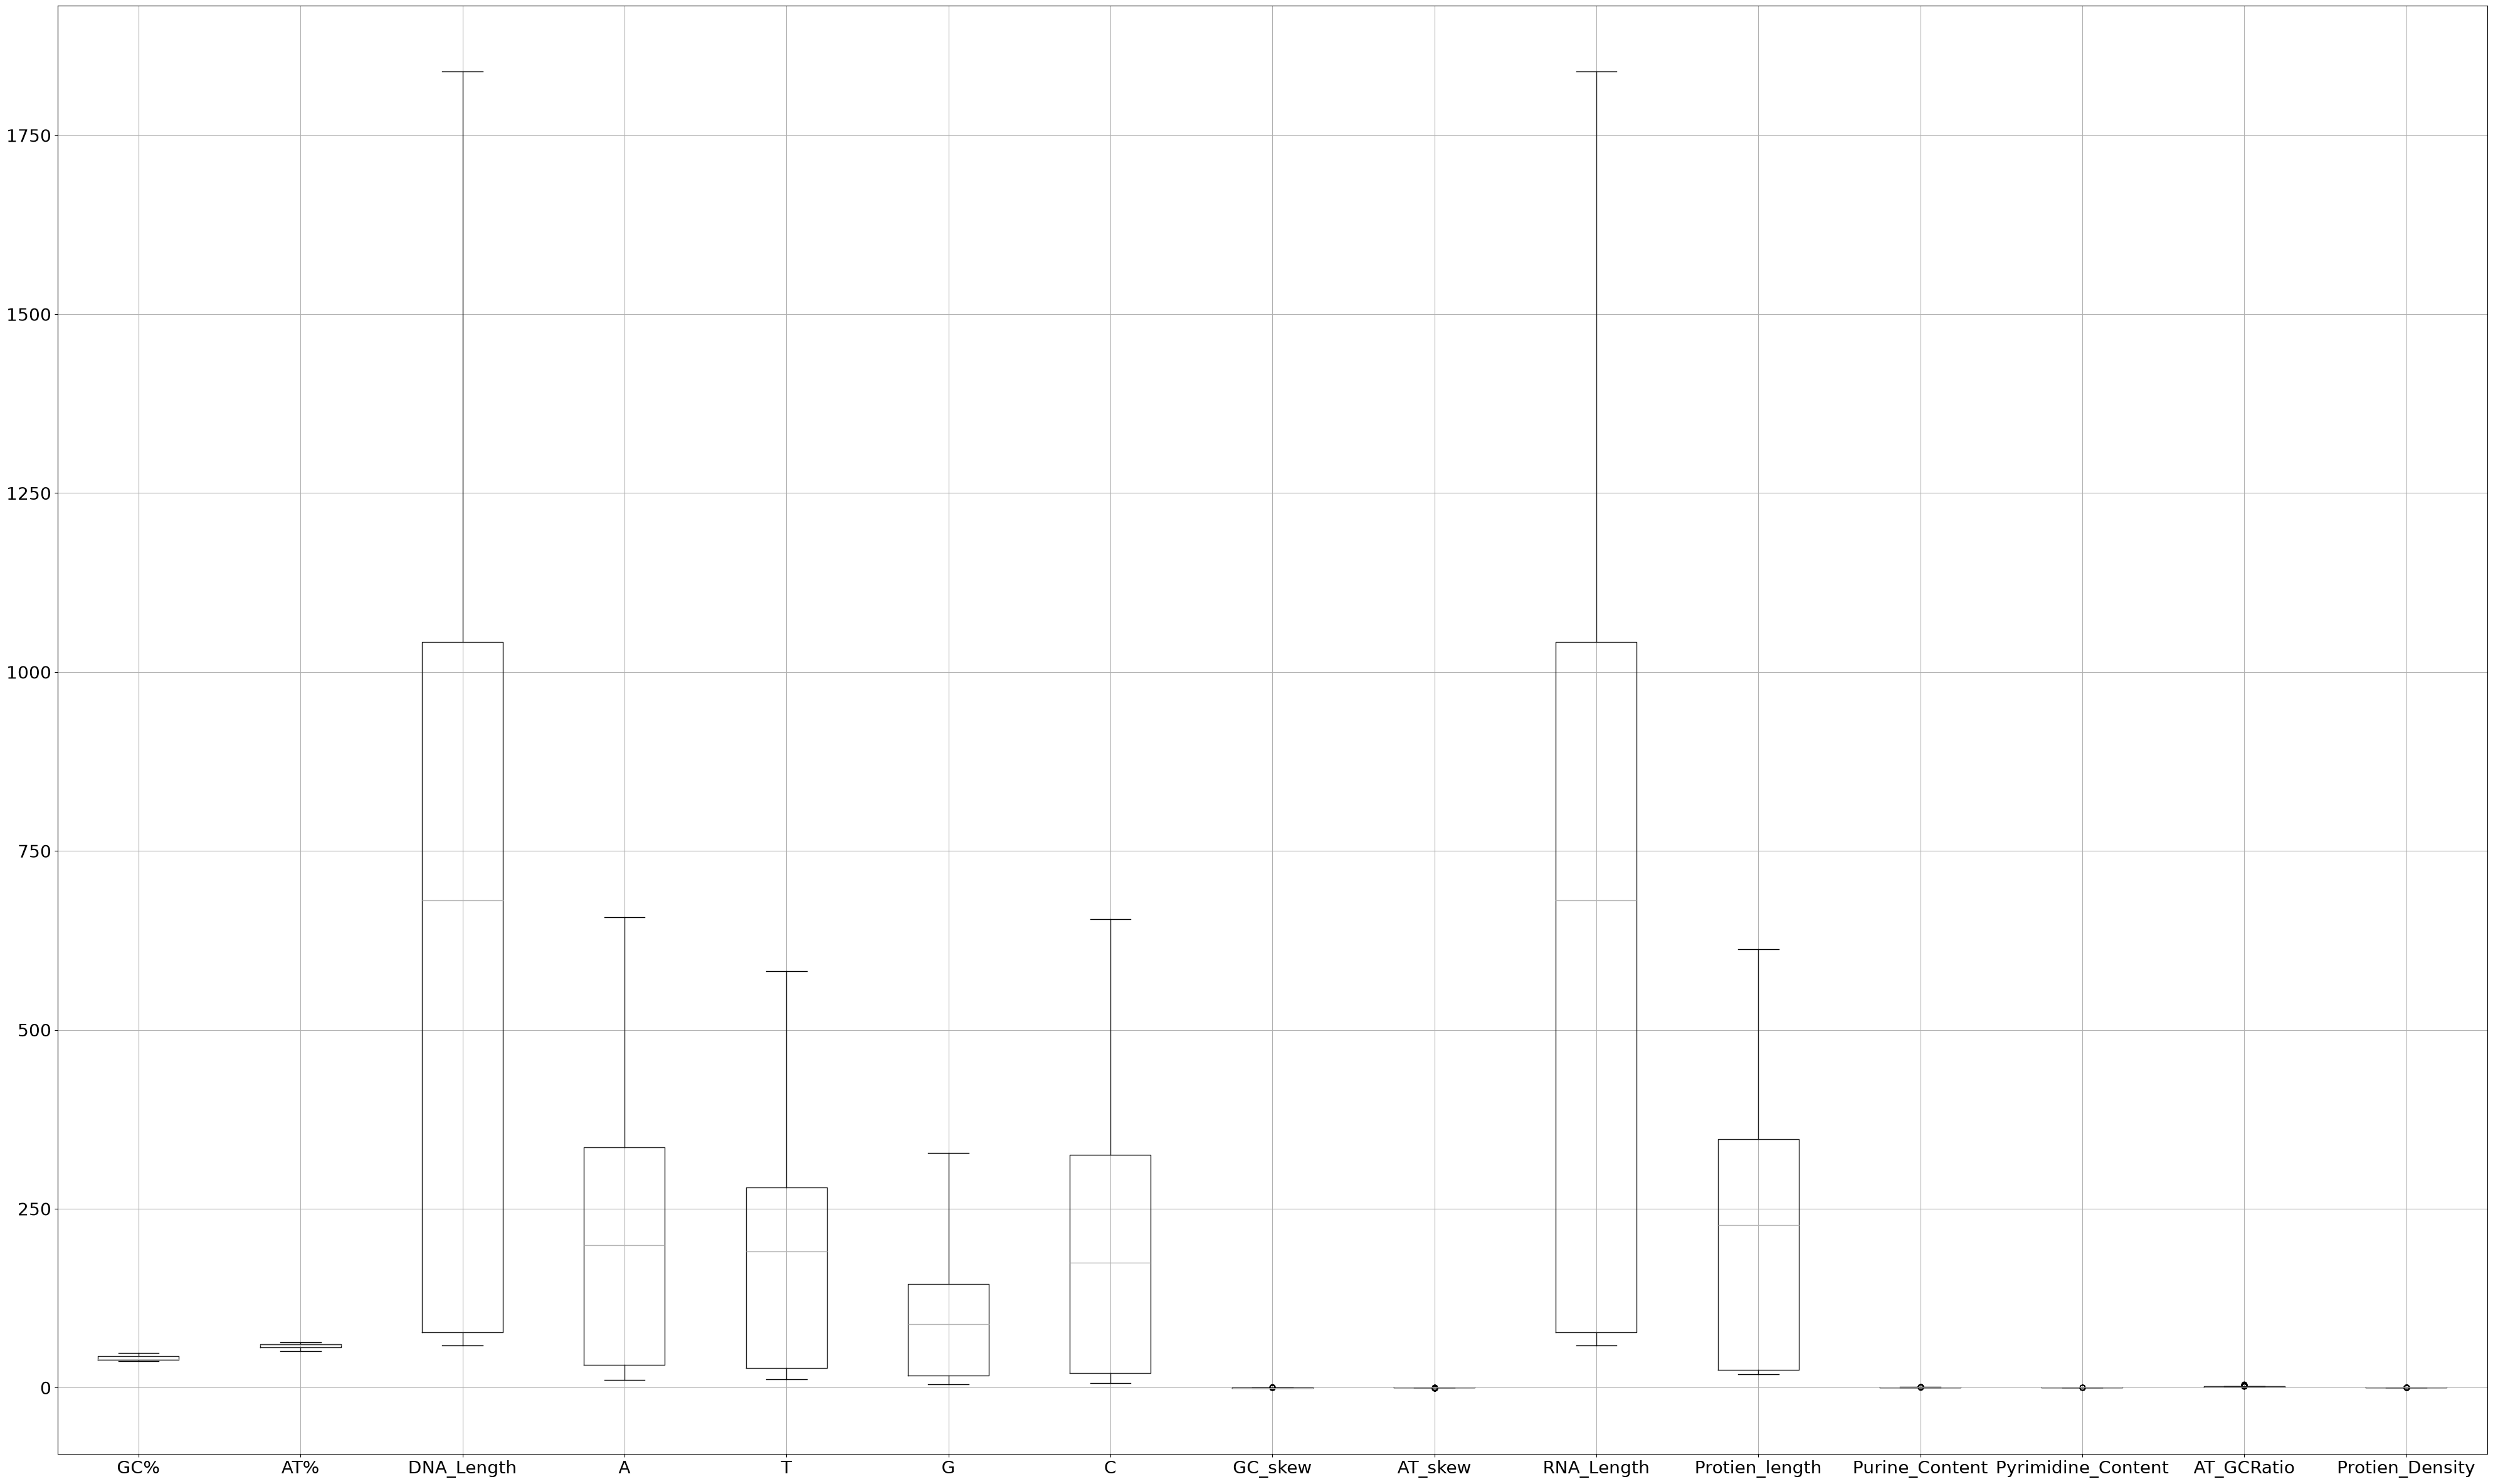

In [771]:

df.boxplot(fontsize=20,figsize=(50,30))


array([[<Axes: title={'center': 'GC%'}>, <Axes: title={'center': 'AT%'}>,
        <Axes: title={'center': 'DNA_Length'}>,
        <Axes: title={'center': 'A'}>],
       [<Axes: title={'center': 'T'}>, <Axes: title={'center': 'G'}>,
        <Axes: title={'center': 'C'}>,
        <Axes: title={'center': 'GC_skew'}>],
       [<Axes: title={'center': 'AT_skew'}>,
        <Axes: title={'center': 'RNA_Length'}>,
        <Axes: title={'center': 'Protien_length'}>,
        <Axes: title={'center': 'Purine_Content'}>],
       [<Axes: title={'center': 'Pyrimidine_Content'}>,
        <Axes: title={'center': 'AT_GCRatio'}>,
        <Axes: title={'center': 'Protien_Density'}>, <Axes: >]],
      dtype=object)

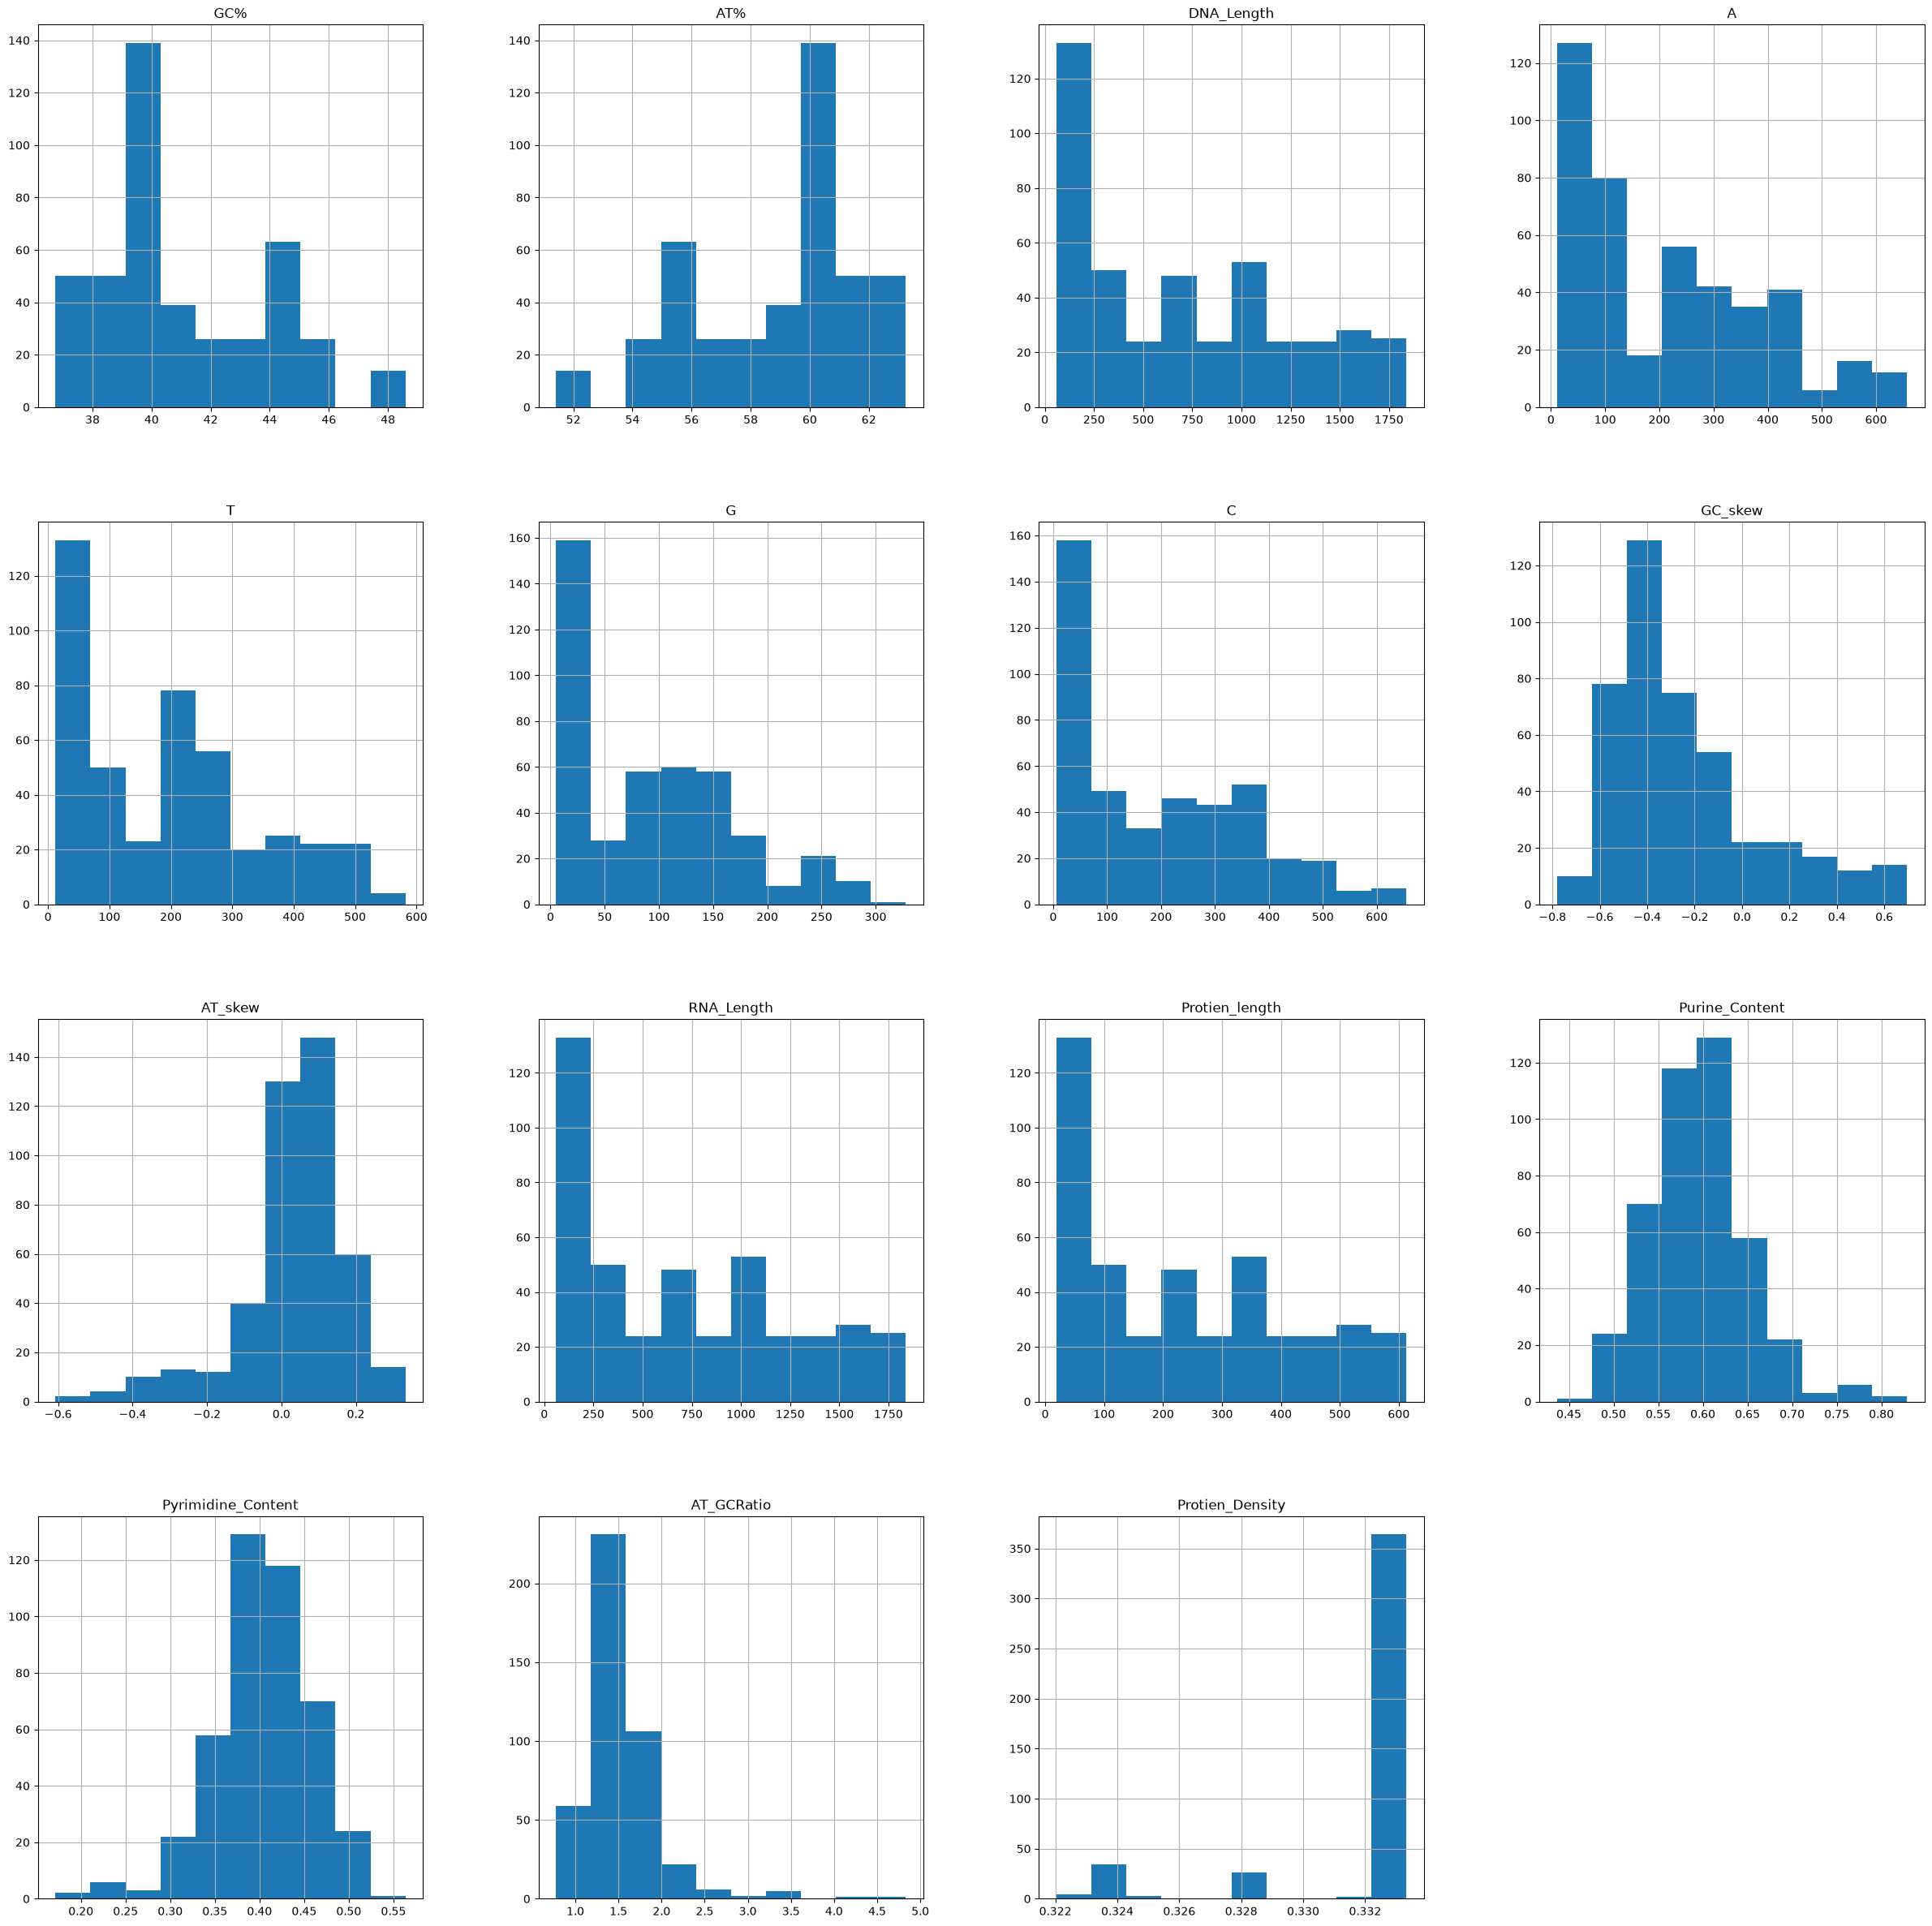

In [768]:
df.hist(figsize=(30,30))

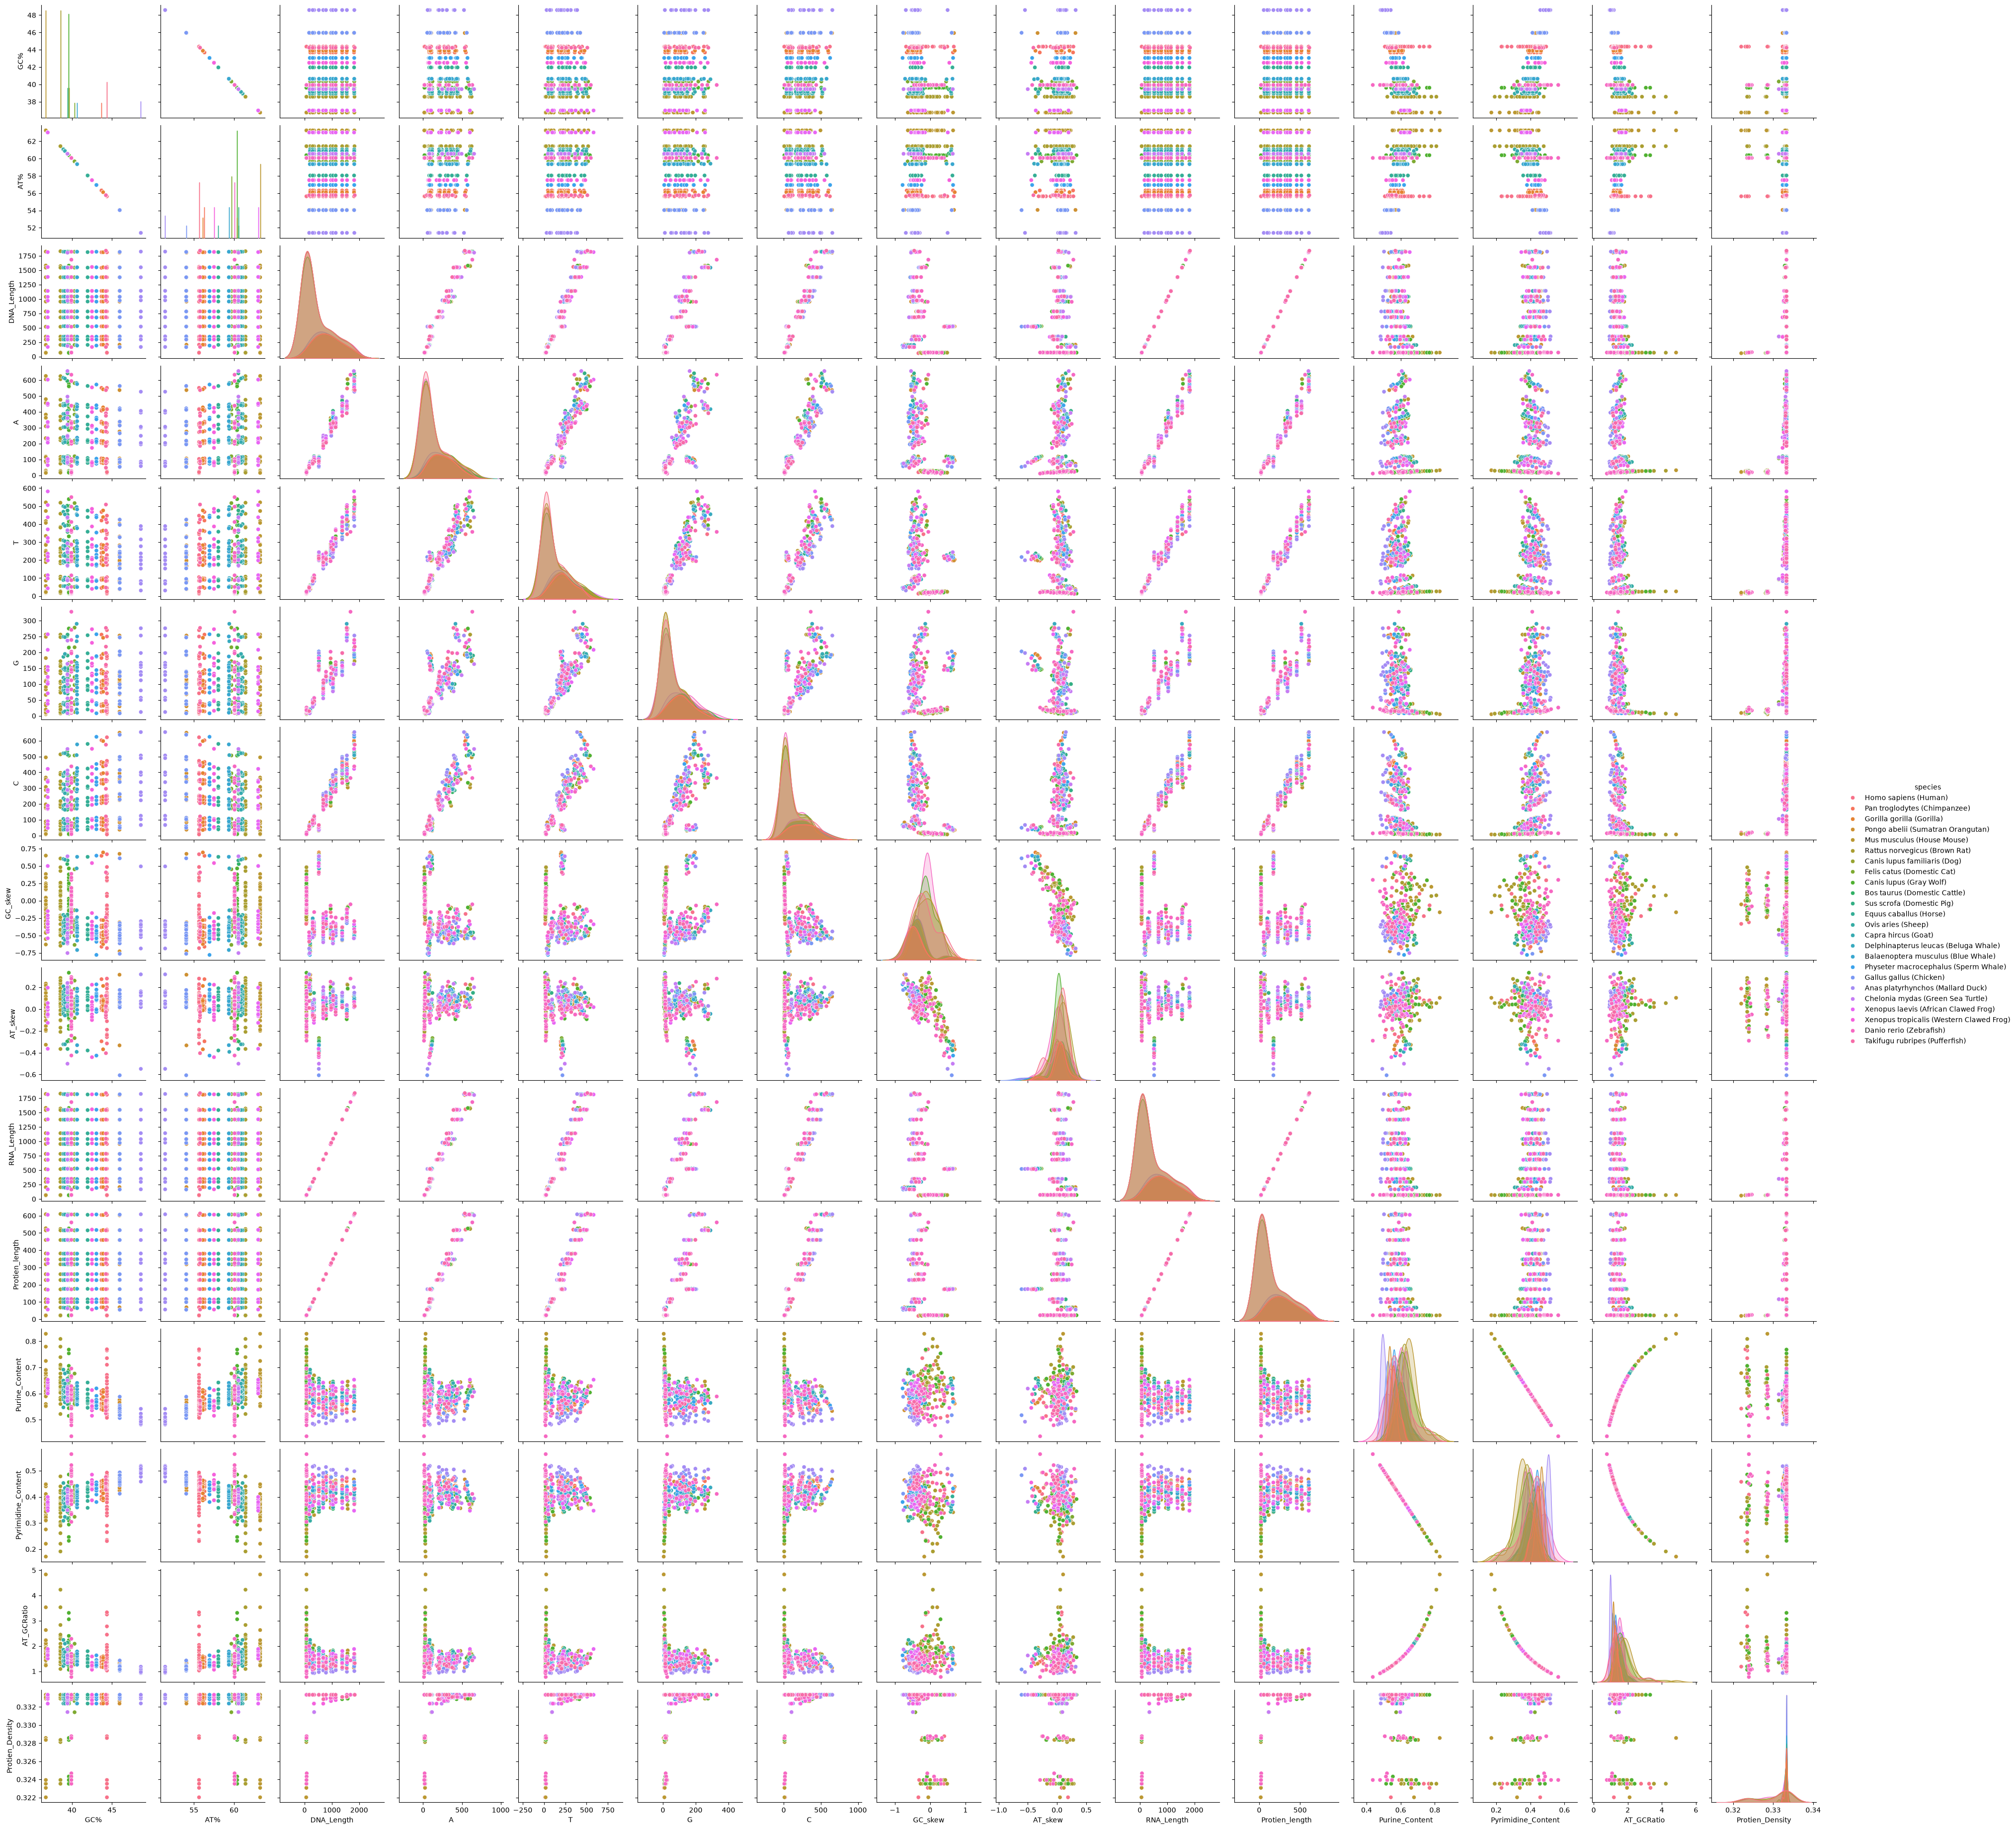

In [774]:
import seaborn as sb
plt.Figure(figsize=(50,60))
sb.pairplot(df,hue='species')

In [335]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

stand=StandardScaler()
stand.fit(df.loc[:,['GC%','AT%',"DNA_Length","A",'T','G',"C","GC_skew",'AT_skew','RNA_Length','Protien_length','Purine_Content','Pyrimidine_Content','Protien_Density','AT_GCRatio']],df.loc[:,'species'])

StandardScaler()

In [336]:
X_scaled=stand.transform(df.loc[:,['GC%','AT%',"DNA_Length","A",'T','G',"C","GC_skew",'AT_skew','RNA_Length','Protien_length','Purine_Content','Pyrimidine_Content','Protien_Density','AT_GCRatio']])
X_scaled.shape
X_scaled

array([[ 1.14931449, -1.14931449, -1.11526693, ...,  0.06917369,
        -2.73986673, -0.18160985],
       [ 1.14931449, -1.14931449,  0.5008225 , ...,  0.91655152,
         0.45952377, -0.75764012],
       [ 1.14931449, -1.14931449, -1.11892739, ...,  0.28503243,
         0.45952377, -0.34043904],
       ...,
       [ 1.10725679, -1.10725679,  2.12057238, ...,  0.48418298,
         0.45952377, -0.47923932],
       [ 1.10725679, -1.10725679, -0.28983507, ...,  0.41107837,
         0.45952377, -0.42911273],
       [ 1.10725679, -1.10725679,  0.83575383, ...,  0.8644102 ,
         0.45952377, -0.72561526]], shape=(433, 15))

In [337]:
Hot_one_encoded=pd.get_dummies(df.loc[:,['Gene']])

Hot_one_encoded


,Gene_ATP6,Gene_ATP8,Gene_COX1,Gene_COX2,Gene_COX3,Gene_CYTB,Gene_MT-RNR1,Gene_MT-RNR2,Gene_MT-TA,Gene_MT-TC,...,Gene_MT-TV,Gene_MT-TW,Gene_MT-TY,Gene_ND1,Gene_ND2,Gene_ND3,Gene_ND4,Gene_ND4L,Gene_ND5,Gene_ND6
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
428,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
429,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
430,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
431,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [338]:
numeric_data=pd.DataFrame(X_scaled,columns=['GC%','AT%',"DNA_Length","A",'T','G',"C","GC_skew",'AT_skew','RNA_Length','Protien_length','Purine_Content','Pyrimidine_Content','Protien_Density','AT_GCRatio'])

In [339]:
numeric_data

,GC%,AT%,DNA_Length,A,T,G,C,GC_skew,AT_skew,RNA_Length,Protien_length,Purine_Content,Pyrimidine_Content,Protien_Density,AT_GCRatio
0,1.149314,-1.149314,-1.115267,-1.062008,-1.148259,-1.094804,-1.026895,-0.221568,0.766765,-1.115267,-1.117633,-0.069146,0.069174,-2.739867,-0.181610
1,1.149314,-1.149314,0.500822,0.623547,0.105932,1.153936,0.373808,0.240203,1.254495,0.500822,0.501760,-0.916514,0.916552,0.459524,-0.757640
2,1.149314,-1.149314,-1.118927,-1.067800,-1.154966,-1.081654,-1.032881,-0.001097,0.817489,-1.118927,-1.117633,-0.285002,0.285032,0.459524,-0.340439
3,1.149314,-1.149314,1.608109,1.967357,1.038191,2.324333,1.235780,0.161861,1.370214,1.608109,1.605143,-0.434324,0.422661,0.313817,-0.440570
4,1.149314,-1.149314,-1.107946,-1.056216,-1.128138,-1.055352,-1.044853,0.439847,0.369795,-1.107946,-1.106654,0.328030,-0.328006,0.459524,0.136049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
428,1.107257,-1.107257,-0.701636,-0.766602,-0.705603,-0.687138,-0.559994,-0.526714,-0.649675,-0.701636,-0.700433,-1.093730,1.093770,0.459524,-0.863540
429,1.107257,-1.107257,1.282329,0.971084,1.172329,1.377495,1.517118,-0.454403,-0.142009,1.282329,1.281264,-1.097997,1.098037,0.377280,-0.866035
430,1.107257,-1.107257,2.120572,1.909434,2.144830,1.640505,2.301272,-0.668628,-0.057619,2.120572,2.121153,-0.484150,0.484183,0.459524,-0.479239
431,1.107257,-1.107257,-0.289835,-0.685510,0.139466,0.838323,-0.745557,2.075094,-3.121500,-0.289835,-0.288723,-0.411047,0.411078,0.459524,-0.429113


In [340]:
Label=LabelEncoder()
Label.fit(df['species'])
species=Label.transform(df['species'])
Label.classes_

array(['Anas platyrhynchos (Mallard Duck)',
       'Balaenoptera musculus (Blue Whale)',
       'Bos taurus (Domestic Cattle)', 'Canis lupus (Gray Wolf)',
       'Canis lupus familiaris (Dog)', 'Capra hircus (Goat)',
       'Chelonia mydas (Green Sea Turtle)', 'Danio rerio (Zebrafish)',
       'Delphinapterus leucas (Beluga Whale)', 'Equus caballus (Horse)',
       'Felis catus (Domestic Cat)', 'Gallus gallus (Chicken)',
       'Gorilla gorilla (Gorilla)', 'Homo sapiens (Human)',
       'Mus musculus (House Mouse)', 'Ovis aries (Sheep)',
       'Pan troglodytes (Chimpanzee)',
       'Physeter macrocephalus (Sperm Whale)',
       'Pongo abelii (Sumatran Orangutan)',
       'Rattus norvegicus (Brown Rat)', 'Sus scrofa (Domestic Pig)',
       'Takifugu rubripes (Pufferfish)',
       'Xenopus laevis (African Clawed Frog)',
       'Xenopus tropicalis (Western Clawed Frog)'], dtype=object)

In [341]:
species.shape

(433,)

In [ ]:
proper_proccesed_data=pd.concat((numeric_data,Hot_one_encoded),axis=1)

proper_proccesed_data['species']=species


In [347]:
proper_proccesed_data.shape

(433, 53)

In [348]:
proper_proccesed_data

,GC%,AT%,DNA_Length,A,T,G,C,GC_skew,AT_skew,RNA_Length,...,Gene_MT-TW,Gene_MT-TY,Gene_ND1,Gene_ND2,Gene_ND3,Gene_ND4,Gene_ND4L,Gene_ND5,Gene_ND6,species
0,1.149314,-1.149314,-1.115267,-1.062008,-1.148259,-1.094804,-1.026895,-0.221568,0.766765,-1.115267,...,False,False,False,False,False,False,False,False,False,13
1,1.149314,-1.149314,0.500822,0.623547,0.105932,1.153936,0.373808,0.240203,1.254495,0.500822,...,False,False,False,False,False,False,False,False,False,13
2,1.149314,-1.149314,-1.118927,-1.067800,-1.154966,-1.081654,-1.032881,-0.001097,0.817489,-1.118927,...,False,False,False,False,False,False,False,False,False,13
3,1.149314,-1.149314,1.608109,1.967357,1.038191,2.324333,1.235780,0.161861,1.370214,1.608109,...,False,False,False,False,False,False,False,False,False,13
4,1.149314,-1.149314,-1.107946,-1.056216,-1.128138,-1.055352,-1.044853,0.439847,0.369795,-1.107946,...,False,False,False,False,False,False,False,False,False,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
428,1.107257,-1.107257,-0.701636,-0.766602,-0.705603,-0.687138,-0.559994,-0.526714,-0.649675,-0.701636,...,False,False,False,False,False,False,True,False,False,21
429,1.107257,-1.107257,1.282329,0.971084,1.172329,1.377495,1.517118,-0.454403,-0.142009,1.282329,...,False,False,False,False,False,True,False,False,False,21
430,1.107257,-1.107257,2.120572,1.909434,2.144830,1.640505,2.301272,-0.668628,-0.057619,2.120572,...,False,False,False,False,False,False,False,True,False,21
431,1.107257,-1.107257,-0.289835,-0.685510,0.139466,0.838323,-0.745557,2.075094,-3.121500,-0.289835,...,False,False,False,False,False,False,False,False,True,21


In [372]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(proper_proccesed_data.drop('species',axis=1),proper_proccesed_data['species'])

In [373]:
X_train

,GC%,AT%,DNA_Length,A,T,G,C,GC_skew,AT_skew,RNA_Length,...,Gene_MT-TV,Gene_MT-TW,Gene_MT-TY,Gene_ND1,Gene_ND2,Gene_ND3,Gene_ND4,Gene_ND4L,Gene_ND5,Gene_ND6
248,0.330379,-0.330379,2.076647,2.060033,1.916795,1.364344,2.331202,-0.805236,0.354328,2.076647,...,False,False,False,False,False,False,False,False,True,False
283,-0.134319,0.134319,0.189684,0.021149,0.280311,0.430657,0.152330,-0.070719,-0.569040,0.189684,...,False,False,False,False,False,False,False,False,False,False
154,-0.453322,0.453322,-0.871847,-0.789771,-0.859862,-1.002750,-0.811402,-0.916666,0.290268,-0.871847,...,False,False,False,False,False,False,False,False,False,False
36,1.149314,-1.149314,-1.120758,-1.085177,-1.101310,-1.015901,-1.098726,2.021491,-1.036751,-1.120758,...,False,False,False,False,False,False,False,False,False,False
360,-1.361944,1.361944,0.013982,0.079072,0.058984,0.101894,-0.134994,-0.025685,0.142099,0.013982,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,-0.467331,0.467331,1.273178,1.295452,1.514381,0.733119,1.140005,-0.628817,-0.113408,1.273178,...,False,False,False,False,False,False,True,False,False,False
86,-1.443824,1.443824,-1.122588,-1.062008,-1.161672,-1.068503,-1.050839,0.415350,1.172556,-1.122588,...,False,True,False,False,False,False,False,False,False,False
229,-0.520516,0.520516,-0.871847,-0.720263,-0.893396,-1.029051,-0.841332,-0.950821,1.131685,-0.871847,...,False,False,False,False,False,False,False,False,False,False
278,-0.134319,0.134319,0.665543,0.982668,0.562001,0.101894,0.613245,-0.787296,0.888502,0.665543,...,False,False,False,False,True,False,False,False,False,False


In [574]:
from sklearn.neighbors import KNeighborsClassifier

knn=KNeighborsClassifier()
knn.fit(X_train,Y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](24,)","[ 0, 1, 2,...,21,22,23]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [575]:

predicted=knn.predict(X_test)


['Anas platyrhynchos (Mallard Duck)' 'Balaenoptera musculus (Blue Whale)'
 'Bos taurus (Domestic Cattle)' 'Canis lupus (Gray Wolf)'
 'Canis lupus familiaris (Dog)' 'Capra hircus (Goat)'
 'Chelonia mydas (Green Sea Turtle)' 'Danio rerio (Zebrafish)'
 'Delphinapterus leucas (Beluga Whale)' 'Equus caballus (Horse)'
 'Felis catus (Domestic Cat)' 'Gallus gallus (Chicken)'
 'Gorilla gorilla (Gorilla)' 'Homo sapiens (Human)'
 'Mus musculus (House Mouse)' 'Ovis aries (Sheep)'
 'Pan troglodytes (Chimpanzee)' 'Physeter macrocephalus (Sperm Whale)'
 'Pongo abelii (Sumatran Orangutan)' 'Rattus norvegicus (Brown Rat)'
 'Sus scrofa (Domestic Pig)' 'Takifugu rubripes (Pufferfish)'
 'Xenopus laevis (African Clawed Frog)'
 'Xenopus tropicalis (Western Clawed Frog)']


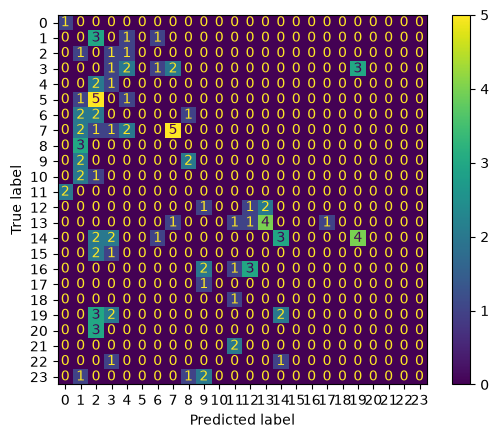

In [576]:
from sklearn.metrics import ConfusionMatrixDisplay,classification_report,accuracy_score,recall_score,f1_score
ConfusionMatrixDisplay.from_predictions(Y_test,predicted)
print(Label.classes_)


In [577]:
print("accuracy_score",accuracy_score(Y_test,predicted))
print("F1_score",f1_score(Y_test,predicted,average='macro'))

accuracy_score 0.13761467889908258
F1_score 0.09410679476468949


In [578]:
names=list(Label.classes_)
print(classification_report(Y_test,predicted))


              precision    recall  f1-score   support

           0       0.33      1.00      0.50         1
           1       0.00      0.00      0.00         5
           2       0.00      0.00      0.00         3
           3       0.10      0.11      0.11         9
           4       0.00      0.00      0.00         3
           5       0.00      0.00      0.00         7
           6       0.00      0.00      0.00         5
           7       0.62      0.45      0.53        11
           8       0.00      0.00      0.00         3
           9       0.00      0.00      0.00         4
          10       0.00      0.00      0.00         3
          11       0.00      0.00      0.00         2
          12       0.20      0.25      0.22         4
          13       0.67      0.50      0.57         8
          14       0.50      0.25      0.33        12
          15       0.00      0.00      0.00         3
          16       0.00      0.00      0.00         6
          17       0.00    

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [ ]:
from sklearn.tree import DecisionTreeClassifier,plot_tree

Tree=DecisionTreeClassifier(criterion='entropy',)
Tree.fit(X_train,Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

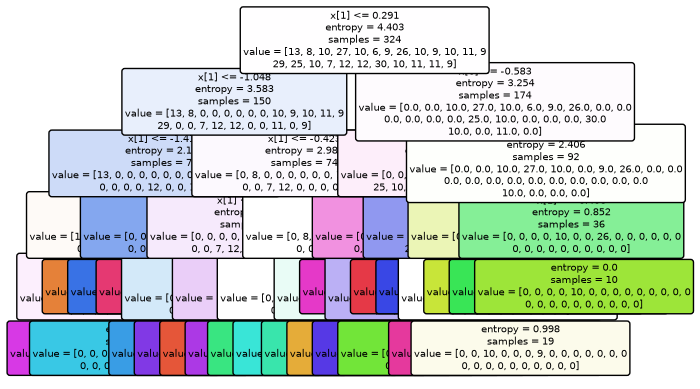

In [779]:
plt.Figure(figsize=(80,150),dpi=200)
plot_tree(Tree,label='all',fontsize=7,filled=True,rounded=True,)
plt.show()

In [695]:
predicted=Tree.predict(X_test)
print(accuracy_score(Y_test,predicted))
print(f1_score(Y_test,predicted,average='macro'))

0.9541284403669725
0.9393939393939394


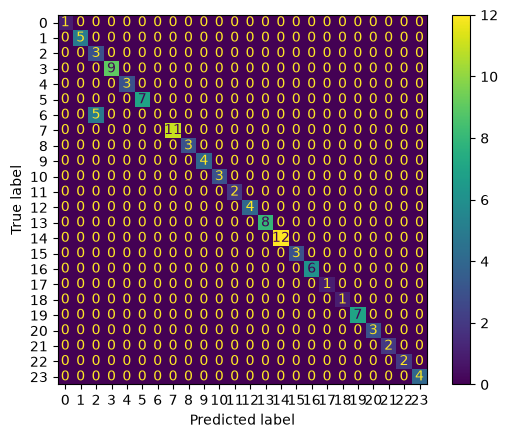

In [696]:

ConfusionMatrixDisplay.from_predictions(Y_test,predicted)

In [697]:
print(classification_report(Y_test,predicted))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         5
           2       0.38      1.00      0.55         3
           3       1.00      1.00      1.00         9
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         7
           6       0.00      0.00      0.00         5
           7       1.00      1.00      1.00        11
           8       1.00      1.00      1.00         3
           9       1.00      1.00      1.00         4
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         4
          13       1.00      1.00      1.00         8
          14       1.00      1.00      1.00        12
          15       1.00      1.00      1.00         3
          16       1.00      1.00      1.00         6
          17       1.00    

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [736]:
from sklearn.ensemble import RandomForestClassifier
random=RandomForestClassifier(criterion='entropy')
random.fit(X_train,Y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `met

In [737]:
predicted=random.predict(X_test)

In [738]:
random.n_estimators

100

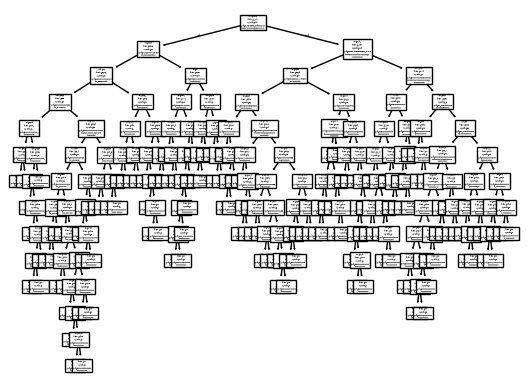

In [780]:
plt.Figure(figsize=(50,120),dpi=200)
plot_tree(random.estimators_[0])
plt.show()

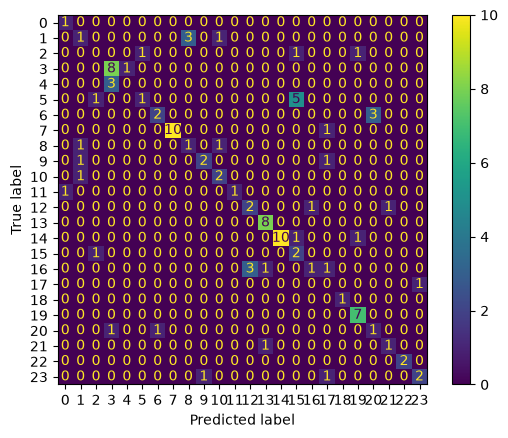

In [740]:
ConfusionMatrixDisplay.from_predictions(Y_test,predicted)

In [741]:
print(classification_report(Y_test,predicted))

              precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       0.25      0.20      0.22         5
           2       0.00      0.00      0.00         3
           3       0.67      0.89      0.76         9
           4       0.00      0.00      0.00         3
           5       0.50      0.14      0.22         7
           6       0.67      0.40      0.50         5
           7       1.00      0.91      0.95        11
           8       0.25      0.33      0.29         3
           9       0.67      0.50      0.57         4
          10       0.50      0.67      0.57         3
          11       1.00      0.50      0.67         2
          12       0.40      0.50      0.44         4
          13       0.80      1.00      0.89         8
          14       1.00      0.83      0.91        12
          15       0.22      0.67      0.33         3
          16       0.50      0.17      0.25         6
          17       0.00    

In [782]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.8/48.9 MB 16.2 MB/s eta 0:00:03
   ---- ----------------------------------- 5.2/48.9 MB 16.9 MB/s eta 0:00:03
   ------ --------------------------------- 8.1/48.9 MB 15.4 MB/s eta 0:00:03
   -------- ------------------------------- 10.5/48.9 MB 14.4 MB/s eta 0:00:03
   ---------- ----------------------------- 13.1/48.9 MB 14.3 MB/s eta 0:00:03
   ------------ --------------------------- 15.5/48.9 MB 13.7 MB/s eta 0:00:03
   ------------- -------------------------- 17.0/48.9 MB 12.7 MB/s eta 0:00:03
   -------------- ------------------------- 17.6/48.9 MB 12.6 MB/s eta 0:00:03
   -------------- ------------------------- 17.6/48.9 MB 12.6 MB/s eta 0:00:03
   ---------------- ----------------------- 19.9/48.9 MB 10.2 MB/s eta 0:00:03
   ------------------ --------------------- 22.5/48.9 MB 10.4 MB/

In [783]:
from xgboost import XGBClassifier

xg=XGBClassifier()


In [784]:
xg.fit(X_train,Y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [ ]:
predicted=xg.predict(X_test)

array([ 6, 21, 12, 10, 16, 19,  3,  3, 15, 13,  7, 22, 16,  1,  3, 16, 16,
        5, 20, 13, 16, 23,  7,  6, 14, 15,  1,  5, 14, 14,  5, 19, 11,  1,
        7, 19, 22,  7,  7, 12,  3,  7, 13, 23, 19, 14,  2, 23, 21,  3,  8,
        7, 19, 12,  5,  5,  9, 23, 11, 10,  2, 16, 13, 20,  7,  7,  1,  9,
       14,  1, 14, 13,  4, 14,  7,  5, 20, 10, 19,  8,  3, 14,  3,  9,  7,
        2, 19, 13, 14,  6,  3,  4, 17,  9, 12,  0,  8,  5, 18, 14, 14,  6,
       13, 14,  3, 15,  4, 13,  6])

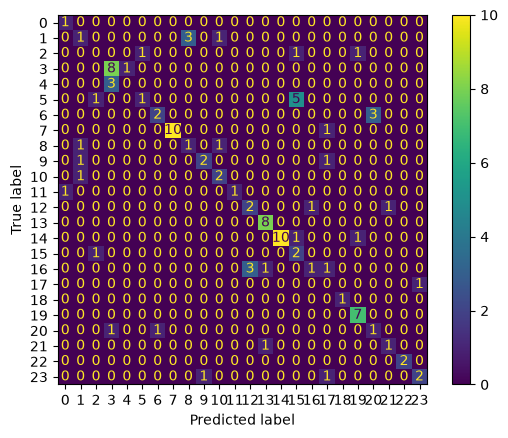

In [786]:
ConfusionMatrixDisplay.from_predictions(Y_test,predicted)

In [787]:
print(classification_report(Y_test,predicted))

              precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       0.25      0.20      0.22         5
           2       0.00      0.00      0.00         3
           3       0.67      0.89      0.76         9
           4       0.00      0.00      0.00         3
           5       0.50      0.14      0.22         7
           6       0.67      0.40      0.50         5
           7       1.00      0.91      0.95        11
           8       0.25      0.33      0.29         3
           9       0.67      0.50      0.57         4
          10       0.50      0.67      0.57         3
          11       1.00      0.50      0.67         2
          12       0.40      0.50      0.44         4
          13       0.80      1.00      0.89         8
          14       1.00      0.83      0.91        12
          15       0.22      0.67      0.33         3
          16       0.50      0.17      0.25         6
          17       0.00    

In [791]:
import pickle as p
with open('models/xgb.pkl','wb') as f:
    p.dump(xg,f)
with open('models/random.pkl','wb') as f:
    p.dump(random,f)
with open('models/tree.pkl','wb') as f:
    p.dump(Tree,f)
with open('models/knn.pkl','wb') as f:
    p.dump(knn,f)